In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
df=pd.read_csv("/content/AEP_hourly.csv")
print(df.head())
df['Datetime']=pd.to_datetime(df['Datetime'])
df=df.sort_values('Datetime').reset_index(drop=True)
data=df[['AEP_MW']].values.astype(float)
scaler=MinMaxScaler(feature_range=(0, 1))
scaled_data=scaler.fit_transform(data)

              Datetime   AEP_MW
0  2004-12-31 01:00:00  13478.0
1  2004-12-31 02:00:00  12865.0
2  2004-12-31 03:00:00  12577.0
3  2004-12-31 04:00:00  12517.0
4  2004-12-31 05:00:00  12670.0


# New section

In [ ]:
def create_sequences(dataset, time_step=60):
    X, y = [], []
    for i in range(len(dataset) - time_step - 1):
        a = dataset[i:(i + time_step), 0]
        X.append(a)
        y.append(dataset[i + time_step, 0])
    return np.array(X), np.array(y)

TIME_STEP = 60
X, y = create_sequences(scaled_data, TIME_STEP)
X = X.reshape(X.shape[0], X.shape[1], 1)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]
print(f"Training shape: {X_train.shape}, Testing shape: {X_test.shape}")

Training shape: (96969, 60, 1), Testing shape: (24243, 60, 1)


In [ ]:
model=Sequential([
    LSTM(64, return_sequences=True, input_shape=(TIME_STEP, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │           825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,163 (117.82 KB)

 Trainable params: 30,163 (117.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1516/1516 ━━━━━━━━━━━━━━━━━━━━ 25s 13ms/step - loss: 0.0045 - mean_absolute_error: 0.0469 - val_loss: 7.3015e-04 - val_mean_absolute_error: 0.0226
Epoch 2/20
1516/1516 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 8.7537e-04 - mean_absolute_error: 0.0227 - val_loss: 4.6965e-04 - val_mean_absolute_error: 0.0167
Epoch 3/20
1516/1516 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - loss: 6.0327e-04 - mean_absolute_error: 0.0187 - val_loss: 3.7158e-04 - val_mean_absolute_error: 0.0146
Epoch 4/20
1516/1516 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - loss: 4.9501e-04 - mean_absolute_error: 0.0169 - val_loss: 7.5335e-04 - val_mean_absolute_error: 0.0217
Epoch 5/20
1516/1516 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - loss: 4.4053e-04 - mean_absolute_error: 0.0159 - val_loss: 0.0011 - val_mean_absolute_error: 0.0260
Epoch 6/20
1516/1516 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - loss: 4.0011e-04 - mean_absolute_error: 0.0151 - val_loss: 0.0016 - val_mean_absolute_error: 0.0308
Epoch 7/20
1516/1516 ━━━━━━━━━━━━━━━━━━━

3031/3031 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step
758/758 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step


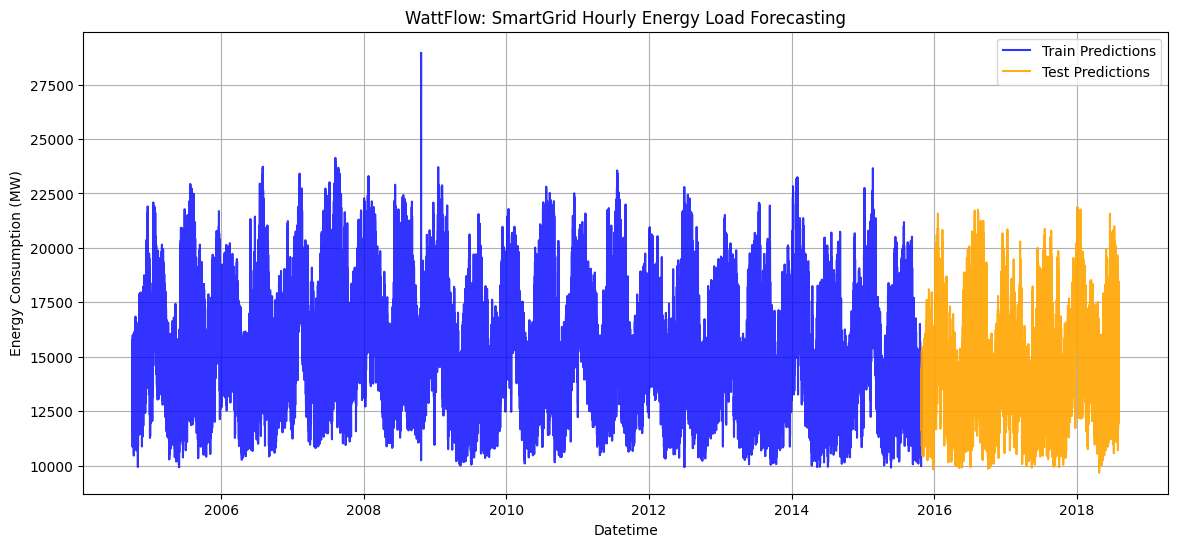

In [ ]:
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)
train_predict = scaler.inverse_transform(train_predict).flatten()
test_predict = scaler.inverse_transform(test_predict).flatten()
train_index = df['Datetime'].iloc[TIME_STEP : TIME_STEP + len(train_predict)]
test_index = df['Datetime'].iloc[train_size + TIME_STEP : train_size + TIME_STEP + len(test_predict)]
plt.figure(figsize=(14, 6))
plt.plot(train_index, train_predict, label='Train Predictions', color='blue', alpha=0.8)
plt.plot(test_index, test_predict, label='Test Predictions', color='orange', alpha=0.9)
plt.title('WattFlow: SmartGrid Hourly Energy Load Forecasting')
plt.xlabel('Datetime')
plt.ylabel('Energy Consumption (MW)')
plt.legend()
plt.grid(True)
plt.show()